# 澳门街景全量特征提取与异常检查

本 Notebook 供 PyCharm 的 Jupyter 编辑器使用。分割和检测流程实现于项目的 `scripts/extract_street_view_features_full.py`，它逐张写入进度日志，可从断点续跑。`RUN_EXTRACTION=True` 时启动或续跑全量推理；已有完整结果时保持 `False` 以快速查看统计和质量标记。

**数据范围：** 仅实际存在的街景图片。无照片的采样点属于正常情况，不生成特征行。预测值带质量标记；`auto_pass` 仅表示未触发自动规则，不等于人工验证通过。

In [1]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/extract_street_view_features_full.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('请从 E:/毕业设计 或其 notebooks 目录运行')
OUT = ROOT / 'outputs/street_view_features_v1'
SCRIPT = ROOT / 'scripts/extract_street_view_features_full.py'
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'font.family':'Microsoft YaHei','axes.unicode_minus':False,'figure.dpi':110})
print('Python:',sys.executable)
print('项目:',ROOT)

Python: C:\Users\25142\anaconda3\python.exe
项目: E:\毕业设计


## 1. 执行或续跑

第一次运行将处理全部不同 SHA-256 图片；中断后再次执行会读取 `unique_progress.jsonl` 跳过已完成图像。只有 `--retry-failed` 才会重试已记录的失败图像。这里的默认值为 `False`，便于快速重现后面的检查。

In [2]:
RUN_EXTRACTION = False
if RUN_EXTRACTION:
    subprocess.run([sys.executable, '-u', str(SCRIPT), '--progress-every', '100'], cwd=ROOT, check=True)
else:
    print('已有结果；如需执行或续跑，将 RUN_EXTRACTION 改为 True 后运行本单元格。')

已有结果；如需执行或续跑，将 RUN_EXTRACTION 改为 True 后运行本单元格。


## 2. 完整性与异常检查

In [3]:
data = pd.read_csv(OUT/'street_view_features_full.csv', encoding='utf-8-sig')
review = pd.read_csv(OUT/'anomaly_review.csv', encoding='utf-8-sig')
summary = json.loads((OUT/'summary.json').read_text(encoding='utf-8'))
params = json.loads((OUT/'parameters.json').read_text(encoding='utf-8'))
assert data.image_id.is_unique
assert len(data) == summary['n_image_rows']
assert data.source_sha256.nunique() == summary['n_unique_sha256']
assert len(review) == summary['n_review_rows']
print('图片记录:',len(data),'不同画面:',data.source_sha256.nunique())
print('处理成功:',summary['n_success_images'],'失败:',summary['n_failed_images'])
print('自动规则未触发:',summary['n_auto_pass'],'需复核:',summary['n_needs_review'])
print('异常复核表行数:',len(review))
print('独立图片推理耗时中位数:',round(summary['median_unique_inference_sec'],3),'秒')
display(data[['image_id','road_id','fclass','point_region','vegetation_share','building_share','sky_share','motor_vehicle_count','person_count','quality_status','quality_flags']].head(8))

图片记录: 5920 不同画面: 5537
处理成功: 5920 失败: 0
自动规则未触发: 1842 需复核: 4078
异常复核表行数: 4107
独立图片推理耗时中位数: 0.819 秒


,image_id,road_id,fclass,point_region,vegetation_share,building_share,sky_share,motor_vehicle_count,person_count,quality_status,quality_flags
0,MC-I000062,MC-R00001,secondary,澳门半岛,0.008472,0.160546,0.550402,9,0,needs_review,bridge_building_review;vehicle_overlap_review
1,MC-I000063,MC-R00001,secondary,澳门半岛,0.016349,0.366646,0.353562,4,0,needs_review,bridge_building_review;vehicle_overlap_review
2,MC-I000078,MC-R00002,secondary,澳门半岛,0.001326,0.585859,0.215230,15,34,needs_review,pedestrian_uncertain_review;vehicle_overlap_re...
3,MC-I000079,MC-R00002,secondary,澳门半岛,0.006099,0.494670,0.289358,17,26,needs_review,pedestrian_uncertain_review;vehicle_overlap_re...
4,MC-I000080,MC-R00006,primary,澳门半岛,0.030834,0.028322,0.650298,10,2,needs_review,vehicle_overlap_review
5,MC-I000081,MC-R00006,primary,澳门半岛,0.023140,0.056839,0.609857,17,1,needs_review,sky_building_seam_conflict;vehicle_overlap_review
6,MC-I000082,MC-R00006,primary,澳门半岛,0.013855,0.015032,0.693700,15,1,needs_review,vehicle_overlap_review
7,MC-I000083,MC-R00006,primary,澳门半岛,0.021125,0.014538,0.701402,10,2,needs_review,vehicle_overlap_review


## 3. 质量标记与特征分布

图中只用于了解预测的分布和复核量；模型质量要以人工标注的掩膜与目标框评估。精确重复图在分布图中仅出现一次，避免重复计权。

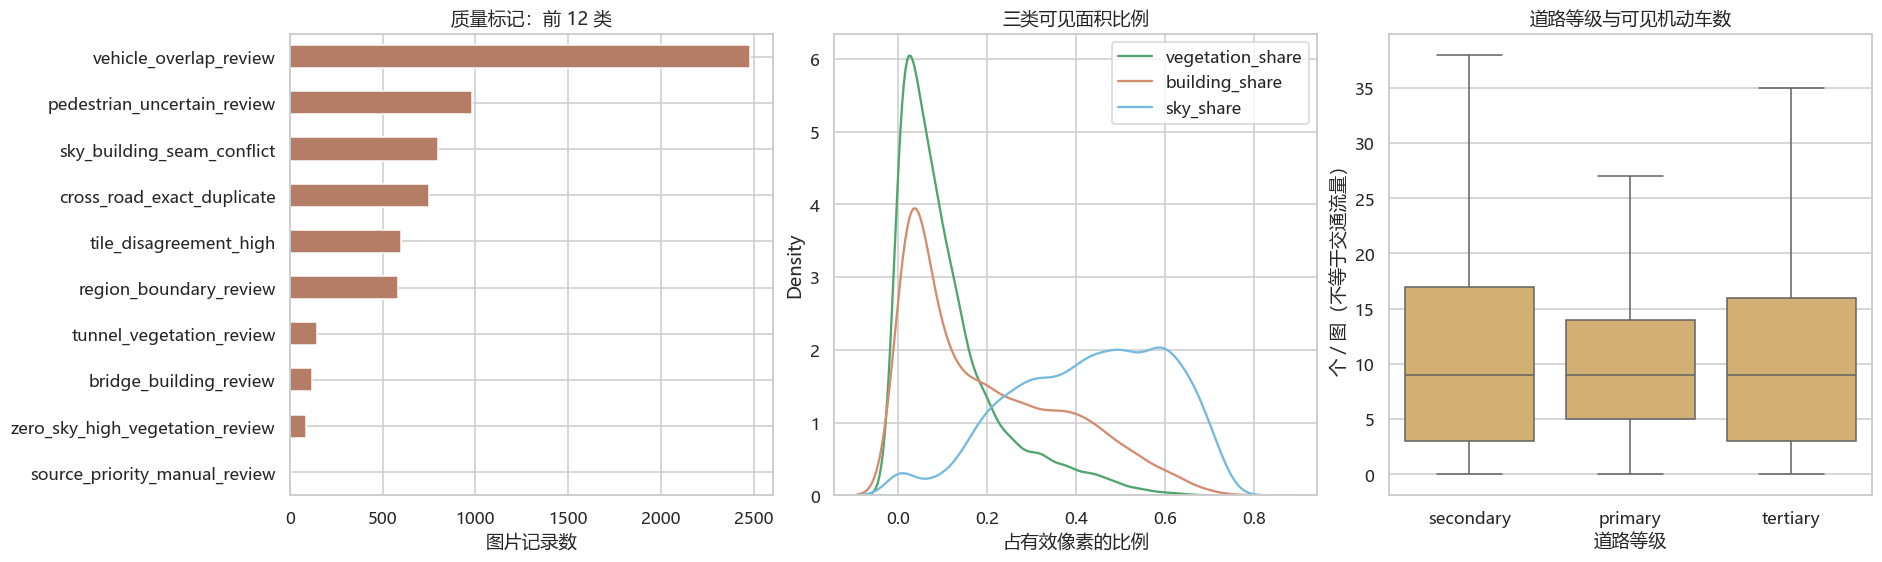

,图片记录数
vehicle_overlap_review,2481
pedestrian_uncertain_review,981
sky_building_seam_conflict,798
cross_road_exact_duplicate,747
tile_disagreement_high,599
region_boundary_review,584
tunnel_vegetation_review,143
bridge_building_review,117
zero_sky_high_vegetation_review,87
source_priority_manual_review,3


In [4]:
unique = data.drop_duplicates('source_sha256')
successful = unique[unique.process_status=='success'].copy()
flag_counts = pd.Series(summary['flag_counts']).sort_values(ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(17,5), layout='constrained')
flag_counts.head(12).sort_values().plot.barh(ax=axes[0], color='#b67d66')
axes[0].set_title('质量标记：前 12 类'); axes[0].set_xlabel('图片记录数')
for name, color in [('vegetation_share','#4fa56b'),('building_share','#d38c6e'),('sky_share','#74b9de')]:
    sns.kdeplot(data=successful, x=name, ax=axes[1], label=name, color=color, fill=False)
axes[1].set_title('三类可见面积比例'); axes[1].set_xlabel('占有效像素的比例'); axes[1].legend()
sns.boxplot(data=successful, x='fclass', y='motor_vehicle_count', ax=axes[2], color='#e2b464', showfliers=False)
axes[2].set_title('道路等级与可见机动车数'); axes[2].set_xlabel('道路等级'); axes[2].set_ylabel('个／图（不等于交通流量）')
fig.savefig(OUT/'全量特征与异常概览.png', dpi=170, bbox_inches='tight')
plt.show()
display(flag_counts.head(15).rename('图片记录数').to_frame())

## 4. 待人工复核记录

优先查看 `review_priority=high`。跨道路完全重复图、区域边界附近图、隧道／桥梁和切片冲突都保留原始预测，不在表中自动改值。

In [5]:
display(review[['image_id','road_id','fclass','quality_status','quality_flags','statistical_tail_fields','review_priority']].head(20))
print('高优先级:',(review.review_priority=='high').sum())
print('参数文件:',OUT/'parameters.json')
print('完整特征表:',OUT/'street_view_features_full.csv')

,image_id,road_id,fclass,quality_status,quality_flags,statistical_tail_fields,review_priority
0,MC-I000062,MC-R00001,secondary,needs_review,bridge_building_review;vehicle_overlap_review,NaN,normal
1,MC-I000063,MC-R00001,secondary,needs_review,bridge_building_review;vehicle_overlap_review,NaN,normal
2,MC-I000078,MC-R00002,secondary,needs_review,pedestrian_uncertain_review;vehicle_overlap_re...,NaN,normal
3,MC-I000079,MC-R00002,secondary,needs_review,pedestrian_uncertain_review;vehicle_overlap_re...,NaN,normal
4,MC-I000080,MC-R00006,primary,needs_review,vehicle_overlap_review,NaN,normal
5,MC-I000081,MC-R00006,primary,needs_review,sky_building_seam_conflict;vehicle_overlap_review,NaN,high
6,MC-I000082,MC-R00006,primary,needs_review,vehicle_overlap_review,NaN,high
7,MC-I000083,MC-R00006,primary,needs_review,vehicle_overlap_review,NaN,normal
8,MC-I000084,MC-R00006,primary,needs_review,vehicle_overlap_review,NaN,normal
9,MC-I000086,MC-R00006,primary,needs_review,vehicle_overlap_review,NaN,normal


高优先级: 1306
参数文件: E:\毕业设计\outputs\street_view_features_v1\parameters.json
完整特征表: E:\毕业设计\outputs\street_view_features_v1\street_view_features_full.csv


## 5. 源表一致性与文件验证

逐图核对源表、道路关联、文件可访问性、特征范围和重复图片一致性。验证统计保存为 JSON。

In [6]:
from collections import Counter
src = pd.read_csv(ROOT/'outputs/structured_data_v1/tables/images.csv', encoding='utf-8-sig')
assoc = pd.read_csv(ROOT/'outputs/image_road_linkage_v1/image_road_association.csv', encoding='utf-8-sig')
joined = data.merge(src[['image_id','sample_id','sha256','relative_path']], on='image_id', how='outer', indicator=True, suffixes=('','_source'), validate='one_to_one')
link = data.merge(assoc[['image_id','road_id']], on='image_id', how='outer', indicator=True, suffixes=('','_assoc'), validate='one_to_one')
feature_cols = ['vegetation_share','building_share','sky_share','motor_vehicle_count','person_count']
validation = {
 'image_rows': int(len(data)), 'source_rows': int(len(src)),
 'source_id_mismatch': int((joined['_merge']!='both').sum()),
 'sample_id_mismatch': int((joined['sample_id']!=joined['sample_id_source']).sum()),
 'sha256_mismatch': int((joined['source_sha256']!=joined['sha256']).sum()),
 'relative_path_mismatch': int((joined['relative_path']!=joined['relative_path_source']).sum()),
 'road_id_mismatch': int(((link['_merge']!='both') | (link['road_id']!=link['road_id_assoc'])).sum()),
 'image_files_missing': int(sum(not (ROOT/'outputs/structured_data_v1'/rel).is_file() for rel in src.relative_path)),
 'required_feature_null_cells': int(data[feature_cols].isna().sum().sum()),
 'share_out_of_range_rows': int((~data[['vegetation_share','building_share','sky_share']].apply(lambda s:s.between(0,1)).all(axis=1)).sum()),
 'share_sum_over_one_rows': int(data[['vegetation_share','building_share','sky_share']].sum(axis=1).gt(1.00001).sum()),
 'negative_count_rows': int(data[['motor_vehicle_count','person_count']].lt(0).any(axis=1).sum()),
 'duplicate_feature_conflict_groups': int(sum(data.groupby('source_sha256')[col].nunique(dropna=False).gt(1).sum() for col in feature_cols)),
 'failed_image_rows': int(data.process_status.ne('success').sum()),
 'anomaly_rows': int(len(review)),
 'anomaly_ids_outside_full_table': int((~review.image_id.isin(data.image_id)).sum()),
}
assert all(v==0 for k,v in validation.items() if k.endswith(('mismatch','missing','cells','rows','groups')) and k not in {'image_rows','source_rows','anomaly_rows','failed_image_rows'})
assert validation['anomaly_ids_outside_full_table']==0
assert validation['image_rows']==validation['source_rows']==5920 and validation['failed_image_rows']==0
(OUT/'validation.json').write_text(json.dumps(validation,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.Series(validation,name='检查结果').to_frame())

,检查结果
image_rows,5920
source_rows,5920
source_id_mismatch,0
sample_id_mismatch,0
sha256_mismatch,0
relative_path_mismatch,0
road_id_mismatch,0
image_files_missing,0
required_feature_null_cells,0
share_out_of_range_rows,0


## 6. 区域与道路等级对比

四个区域按现有采样点区域归属字段统计。边界未定记录不纳入区域对比；跨道路精确重复图片先排除，再按 SHA-256 去重，避免同一画面重复计入。图中为模型预测的描述性结果，尚未完成全量人工准确率评估。

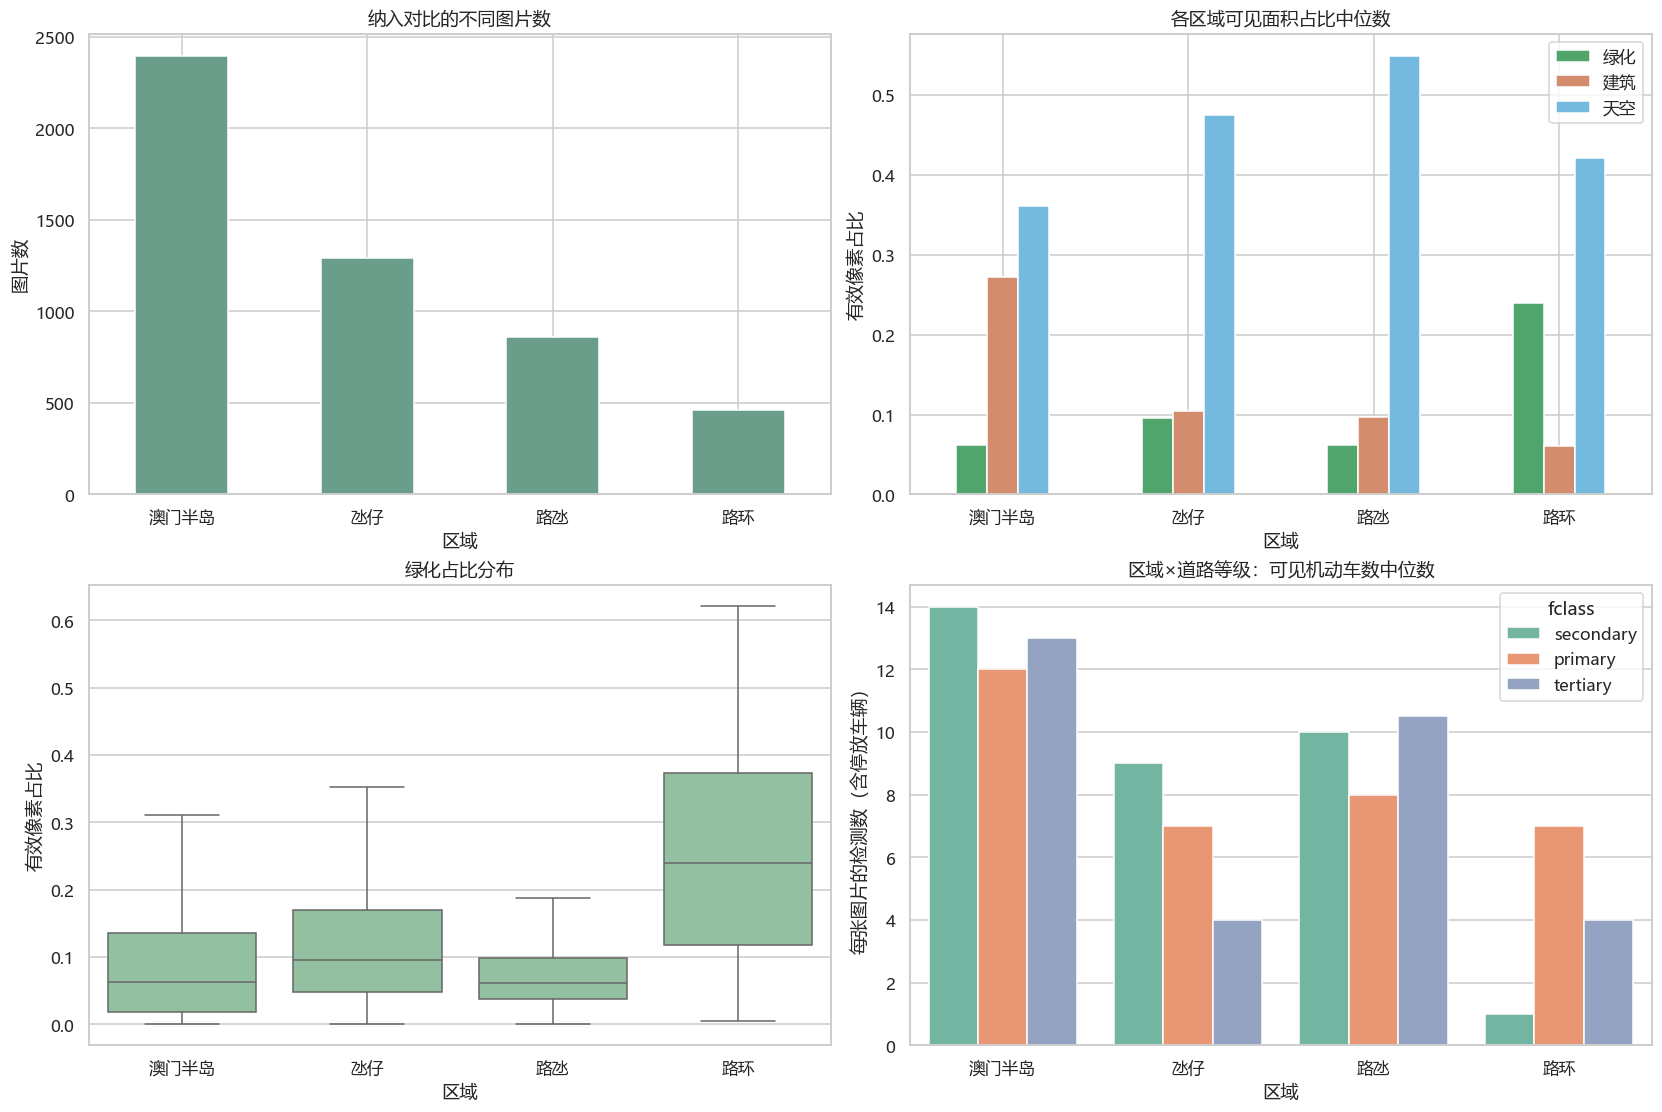

,point_region,fclass,images,vegetation_median,building_median,sky_median,vehicle_median,person_median,flagged_images
0,氹仔,primary,724,0.096,0.077,0.504,7.0,1.0,412
1,氹仔,secondary,267,0.074,0.230,0.428,9.0,2.0,161
2,氹仔,tertiary,299,0.131,0.137,0.426,4.0,1.0,112
3,澳门半岛,primary,1254,0.057,0.163,0.462,12.0,3.0,894
4,澳门半岛,secondary,473,0.083,0.318,0.321,14.0,7.0,365
5,澳门半岛,tertiary,671,0.060,0.410,0.250,13.0,8.0,505
6,路氹,primary,523,0.071,0.066,0.581,8.0,1.0,296
7,路氹,secondary,197,0.044,0.184,0.470,10.0,1.0,126
8,路氹,tertiary,140,0.060,0.131,0.512,10.5,2.0,71
9,路环,primary,2,0.108,0.053,0.557,7.0,0.5,2


纳入区域对比: 5007 排除边界未定: 168 跨道路重复图记录: 747


In [7]:
regions=['澳门半岛','氹仔','路氹','路环']
valid = data[(data.process_status=='success') & (data.point_region.isin(regions)) & (~data.quality_flags.fillna('').str.contains('cross_road_exact_duplicate'))].drop_duplicates('source_sha256').copy()
assert len(valid)>0
summary_region = valid.groupby(['point_region','fclass'],observed=True).agg(
 images=('image_id','size'),
 vegetation_median=('vegetation_share','median'),building_median=('building_share','median'),sky_median=('sky_share','median'),
 vehicle_median=('motor_vehicle_count','median'),person_median=('person_count','median'),
 flagged_images=('quality_status',lambda s:int((s=='needs_review').sum()))
).reset_index()
summary_region.to_csv(OUT/'区域道路等级街景特征汇总.csv',index=False,encoding='utf-8-sig')
fig, axes=plt.subplots(2,2,figsize=(15,10),layout='constrained')
region_counts=valid.point_region.value_counts().reindex(regions)
region_counts.plot.bar(ax=axes[0,0],color='#6b9e8a')
axes[0,0].set_title('纳入对比的不同图片数'); axes[0,0].set_xlabel('区域'); axes[0,0].set_ylabel('图片数'); axes[0,0].tick_params(axis='x',rotation=0)
med=valid.groupby('point_region')[['vegetation_share','building_share','sky_share']].median().reindex(regions)
med.rename(columns={'vegetation_share':'绿化','building_share':'建筑','sky_share':'天空'}).plot.bar(ax=axes[0,1],color=['#4fa56b','#d38c6e','#74b9de'])
axes[0,1].set_title('各区域可见面积占比中位数'); axes[0,1].set_xlabel('区域'); axes[0,1].set_ylabel('有效像素占比'); axes[0,1].tick_params(axis='x',rotation=0)
sns.boxplot(data=valid,x='point_region',y='vegetation_share',order=regions,ax=axes[1,0],showfliers=False,color='#8bc89d')
axes[1,0].set_title('绿化占比分布'); axes[1,0].set_xlabel('区域'); axes[1,0].set_ylabel('有效像素占比')
sns.barplot(data=valid,x='point_region',y='motor_vehicle_count',hue='fclass',order=regions,estimator='median',errorbar=None,ax=axes[1,1],palette='Set2')
axes[1,1].set_title('区域×道路等级：可见机动车数中位数'); axes[1,1].set_xlabel('区域'); axes[1,1].set_ylabel('每张图片的检测数（含停放车辆）')
fig.savefig(OUT/'区域与街景特征对比.png',dpi=170,bbox_inches='tight')
plt.show()
display(summary_region.round(3))
print('纳入区域对比:',len(valid),'排除边界未定:',int((data.point_region.isin(regions)==False).sum()),'跨道路重复图记录:',summary['n_cross_road_exact_duplicate'])